This notebook demonstrates the functionality of the ``morphing_qec_circuits`` package by walking through examples of how to reproduce the results from arXiv:2604.09797. If you or your AI have any questions or find any mistakes/bugs, please feel free to send me an email at `m.h.shaw@tudelft.nl` (before November 30, 2026).

# Basic usage


There are two classes that we can use to define morphing circuits: CSSMorphingSpecifications, and MorphingSpecifications - the latter of which allows for non-CSS codes and circuits. For now, only stabiliser codes are supported (no subsystem/Floquet codes). To define a morphing circuit object, we need to specify four things:
- the stabilisers of the mid-cycle code,
- which contraction rounds each stabiliser is contracting in, and
- the contraction circuits.

The way that we do this differs slightly depending on whether we are defining a CSSMorphingSpecifications object or a MorphingSpecifications object. Note that for backwards compatibility, you can also initialise a CSSMorphingSpecifications object by passing the same arguments into MorphingSpecifications() - it will automatically detect that you are trying to initialise a CSSMorphingSpecifications object and return a CSSMorphingSpecifications object instead.

Enough talk, let's get to an example: a CSS morphing circuit for the $[[7,1,3]]$ Steane code.

![title](steane_code.jpg)

In [1]:
import numpy as np
from morphing_qec_circuits.morphing import CSSMorphingSpecifications

In [2]:
#stabilisers are defined by listing the indices of the qubits each stabiliser has support on.
#I'm subtracting one from all the indices in the picture because python.
stabilisers = {"X": [[0,1,2,3], [1,2,4,5],[2,3,5,6]], "Z": [[0,1,2,3], [1,2,4,5],[2,3,5,6]]}

#the morphing circuit that we're going to define will contract both red stabilisers in the first contraction round,
#both blue stabilisers in the second, and both green stabilisers in the third.
contraction_rounds = {"X": [[0],[1],[2]], "Z": [[0],[1],[2]]}

#CNOT gates are specified by a length-two list representing the qubit index of the control and the target (respectively).
#Lists of gates represent simultaneously-executable layers of CNOT gates.
#Lists of these layers define an entire contraction round.
#The red contraction circuit works by contracting the X check onto qubit 1 in the diagram (python index 0)
#and the Z check onto qubit 3 (index 2).
#The other contraction circuits are rotations of the first one by 120 degrees.
CNOT_gates = [
    [[[0,3],[1,2]],[[0,1],[3,2]]],
    [[[4,1],[5,2]],[[4,5],[1,2]]],
    [[[6,5],[3,2]],[[6,3],[5,2]]],
]
measurement_lists = {"X": [[0],[4],[6]], "Z": [[2],[2],[2]]}

#adding coordinates is optional, but highly recommended where possible!
#Input coordinates as a complex number for each qubit in the code.
coordinates_list = [
    1/2 + 1j*np.sqrt(3)/2,
    1/4 + 1j*np.sqrt(3)/4,
    1/2 + 1j*np.sqrt(3)/6,
    3/4 + 1j*np.sqrt(3)/4,
    0,
    1/2,
    1,
]

steane_code_morphing_specs = CSSMorphingSpecifications(
    stabilisers,
    contraction_rounds,
    CNOT_gates,
    measurement_lists,
    coordinates_list = coordinates_list,
)

We can visualise the contraction circuits using stim.

In [3]:
import stim

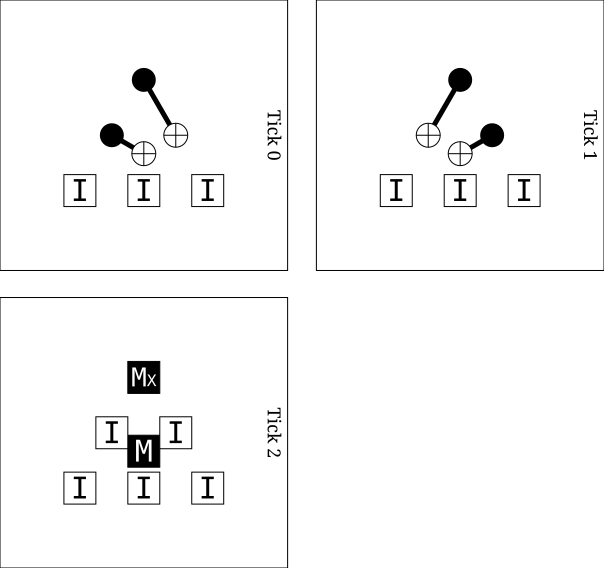

In [4]:
contraction_round = 0

my_circuit = steane_code_morphing_specs.coordinate_circuit()
my_circuit += steane_code_morphing_specs.contraction_circuit(contraction_round)
my_circuit.diagram('timeslice-svg')

CSSMorphingSpecifications comes with methods that automatically calculate $[[n,k,d]]$ parameters of interest using Gurobi. You need a valid Gurobi licence to use these methods, the below cell allows you to specify the location of the Gurobi licence file. The values calculated by these methods are stored as attributes of the CSSMorphingSpecifications object, so if they are called again the distance isn't recalculated.

In [5]:
import os

print(os.environ["GRB_LICENSE_FILE"])
#if that license file location isn't what you expected, you can enter it below.
#os.environ["GRB_LICENSE_FILE"] = "/mnt/c/Users/my_username/gurobi.lic"

In [6]:
#the nkd parameters of the mid-cycle Steane code
print("mid_cycle_nkd:", steane_code_morphing_specs.mid_cycle_nkd_params())
#the nkd parameters of each of the three end-cycle codes
print("end_cycle_nkd:", steane_code_morphing_specs.end_cycle_nkd_params())
#the (spatial) circuit-level distance of the morphing circuit. This can be quite slow for bigger circuits!
print("circuit distance:", steane_code_morphing_specs.calculate_circuit_distance())

Set parameter WLSAccessID
Set parameter WLSSecret
Set parameter LicenseID to value 2861019
Academic license 2861019 - for non-commercial use only - registered to m.___@tudelft.nl
mid_cycle_nkd: (7, 1, 3)
end_cycle_nkd: [(5, 1, 2), (5, 1, 2), (5, 1, 2)]
circuit distance: 2


Yes, the end-cycle distance and the circuit-distance are both only 2, so this circuit isn't the best in practice, I'll leave it as an exercise to the reader to improve on this!

Finally, we can generate a memory experiment automatically, using noise models from the surface_sim package. A few additional noise models and setups that I personally use can be found in ``morphing_qec_circuits.misc``.

In [7]:
from morphing_qec_circuits.misc import SI1000_variable_measurement_setup, ArbitraryGatesSI1000NoiseModel

In [8]:
#Error probability
p = 0.001
#Number of "measurement rounds" of QEC: T = 1 would therefore be going from one end-cycle code to the next, and
# in this example T = 3 would do one full period of the morphing circuit.
T = 5
# basis can be "X", "Z", or "both", depending on what kind of memory experiment you want to define.
basis = "X"

#We will use this noise model later to reproduce some results from arXiv:2604.09797.
# For now, this is simply the SI1000 noise model.
noise_setup = SI1000_variable_measurement_setup(p,1)
noise_model_generator = lambda qubit_dictionary, noise_setup: ArbitraryGatesSI1000NoiseModel(qubit_dictionary, noise_setup)

steane_code_morphing_experiment = steane_code_morphing_specs.get_morphing_memory_circuit(
    noise_setup,
    T,
    noise_model_generator = noise_model_generator,
    basis = basis,
)


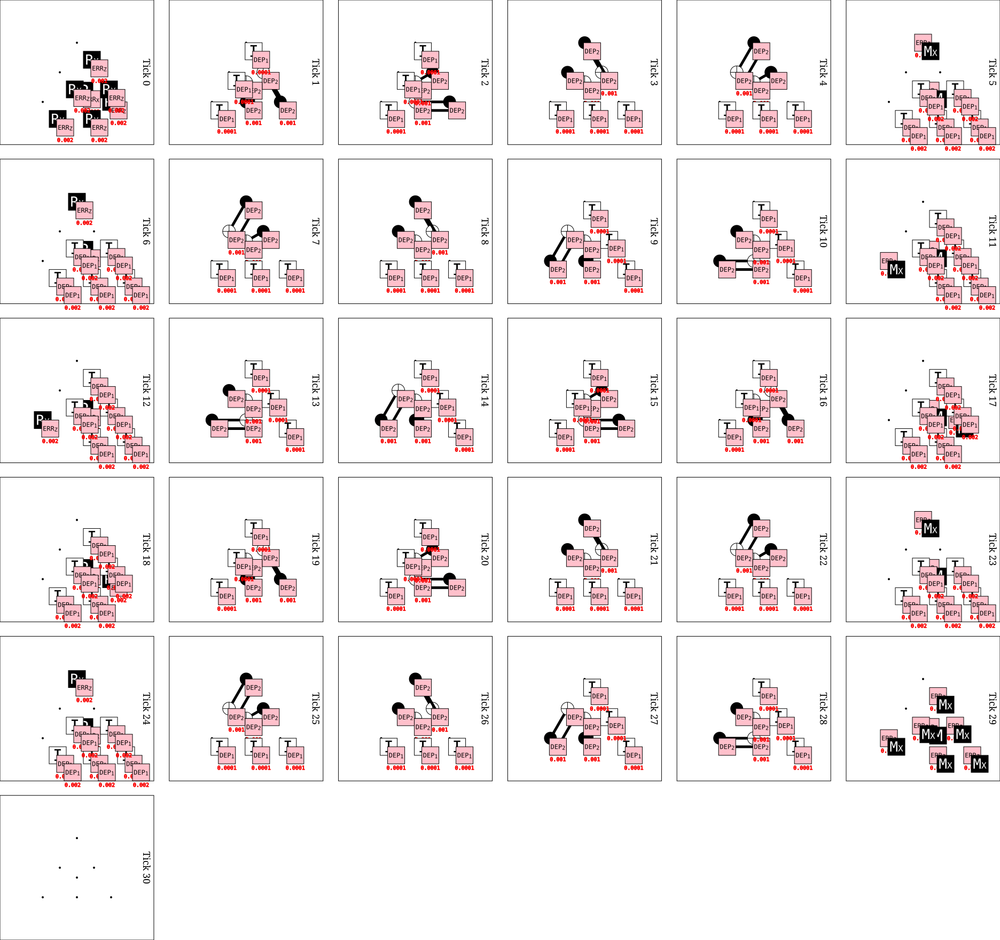

In [9]:
#the gates and noise model
steane_code_morphing_experiment.diagram('timeslice-svg')

#the detectors
#steane_code_morphing_experiment.diagram('detslice-svg')

#the observable(s)
#steane_code_morphing_experiment.diagram('detslice-svg', filter_coords = ["L0", "L1"])

We can sample errors from this circuit using a decoder and using some helper functions from ``morphing_qec_circuits.misc``. You might just want to use ``sinter`` though, I had some trouble using ``sinter`` on a computing cluster once so I have my own sampling function below.

In [10]:
from mle_decoder import MLEDecoder
from morphing_qec_circuits.misc import sample_logical_flips

In [11]:
dem = steane_code_morphing_experiment.detector_error_model()
sampler = dem.compile_sampler()
decoder = MLEDecoder(dem)

#the sampling runs batch_size samples at a time. After each batch, it checks if the number of target_flips
# has been reached and if the max_time has been exceeded. If either of these occur then it stops.
# So in this example, setting target_flips to be ridiculously large and max_time to 10 basically means
# it will take a little over 10 seconds to run.
n_flips, n_shots = sample_logical_flips(
    sampler,
    decoder,
    batch_size=100,
    target_flips=1000000,
    max_time=10,
)

print("number of logical flips:", n_flips)
print("number of shots:", n_shots)
print("logical error probability:", n_flips/n_shots)

number of logical flips: 272
number of shots: 7900
logical error probability: 0.034430379746835445


The decoder above used correlated information about the $X$ and $Z$ checks to decode. To separate the $X$ and $Z$ decoding use the code below.

In [12]:
from morphing_qec_circuits.misc import separate_XZ_dem_from_circuit

In [13]:
dem = steane_code_morphing_experiment.detector_error_model()
sampler = dem.compile_sampler()
separated_dems, separated_detector_indices = separate_XZ_dem_from_circuit(steane_code_morphing_experiment)
separated_decoders = {pauli: MLEDecoder(separated_dems[pauli]) for pauli in ["X", "Z"]}

n_flips, n_shots = sample_logical_flips(
    sampler,
    separated_decoders,
    batch_size=100,
    target_flips=1000000,
    max_time=10,
    separate_XZ=True,
    XZ_detector_indices=separated_detector_indices,
)

print("number of logical flips:", n_flips)
print("number of shots:", n_shots)
print("logical error probability:", n_flips/n_shots)


number of logical flips: 552
number of shots: 7100
logical error probability: 0.07774647887323943


It does a bit worse, which one would expect since we have given the decoder incomplete information about the syndrome.

To demonstrate a non-CSS code, let's use the $[[5,1,3]]$ perfect code. It has stabiliser generators
\begin{align}
ZXXZI&,&IZXXZ&,&ZIZXX&,&XZIZX&,&XXZIZ,
\end{align}
which can be visualised with qubits on the vertices of a square-grid on a twisted torus, and each stabiliser being an $XZZX$ surface code stabiliser, the second stabiliser generator is shown below.

![title](perfect_code.jpg)

In this morphing circuit we're going to contract two stabilisers at a time. The five contraction circuits will be cyclic shifts of the qubits.

In [14]:
from morphing_qec_circuits.morphing import MorphingSpecifications

In [15]:
#stabilisers are defined by stim.PauliString objects, which are more convenient when the code is not CSS.
stabilisers = [stim.PauliString("ZXXZ_"), stim.PauliString("_ZXXZ"), stim.PauliString("Z_ZXX"), stim.PauliString("XZ_ZX"), stim.PauliString("XXZ_Z")]

#we're going to contract the first and third stabilisers in the first contraction round,
# the second and fourth stabilisers in the second contraction round, and so forth.
contraction_rounds = [[0,3],[1,4],[0,2],[1,3],[2,4]]

#contraction circuits are inputted as stim.Circuit objects here,
# to allow for the menagerie of gates that you might need to use to define non-CSS morphing circuits.
contraction_circuits = [
    stim.Circuit("""
    ZCZ 1 0
    XCX 2 3
    TICK
    ZCZ 0 4
    TICK
    XCX 1 3 2 4
    TICK
    MZ 3 2
    """),
    stim.Circuit("""
    ZCZ 2 1
    XCX 3 4
    TICK
    ZCZ 1 0
    TICK
    XCX 2 4 3 0
    TICK
    MZ 4 3
    """),
    stim.Circuit("""
    ZCZ 3 2
    XCX 4 0
    TICK
    ZCZ 2 1
    TICK
    XCX 3 0 4 1
    TICK
    MZ 0 4
    """),
    stim.Circuit("""
    ZCZ 4 3
    XCX 0 1
    TICK
    ZCZ 3 2
    TICK
    XCX 4 1 0 2
    TICK
    MZ 1 0
    """),
    stim.Circuit("""
    ZCZ 0 4
    XCX 1 2
    TICK
    ZCZ 4 3
    TICK
    XCX 0 2 1 3
    TICK
    MZ 2 1
    """),
]

coordinates_list = [
    1j,
    0.6 + 0.8j,
    0.2 + 0.6j,
    0.8 + 0.4j,
    0.4 + 0.2j,
]

perfect_code_morphing_specs = MorphingSpecifications(
    stabilisers,
    contraction_rounds,
    contraction_circuits,
    coordinates_list = coordinates_list,
)

We can do all the same things as before!

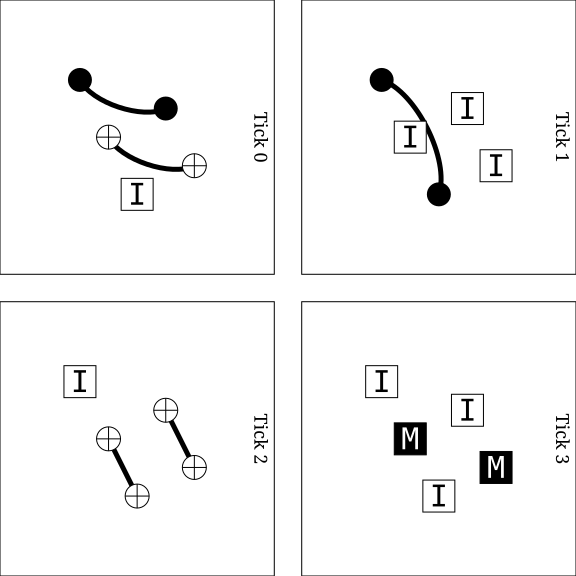

In [16]:
contraction_round = 0

my_circuit = perfect_code_morphing_specs.coordinate_circuit()
my_circuit += perfect_code_morphing_specs.contraction_circuits[contraction_round]
my_circuit.diagram('timeslice-svg')

In [17]:
print("mid_cycle_nkd:", perfect_code_morphing_specs.mid_cycle_nkd_params())
print("end_cycle_nkd:", perfect_code_morphing_specs.end_cycle_nkd_params())
print("circuit distance:", perfect_code_morphing_specs.calculate_circuit_distance())

mid_cycle_nkd: (5, 1, 3)
end_cycle_nkd: [(3, 1, 1), (3, 1, 1), (3, 1, 1), (3, 1, 1), (3, 1, 1)]
circuit distance: 1


Uh oh, the end-cycle and circuit-level distance are both one, but again, I'll leave it as an exercise to improve on this!

The interesting thing here is that because the $[[5,1,3]]$ code has a redundancy between its stabiliser generators, we can define a stability experiment! This can be generated in a similar manner to the memory experiments above.

In [18]:
p = 0.001
T = 10

#We will use this noise model later to reproduce some results from arXiv:2604.09797.
# For now, this is simply the SI1000 noise model.
noise_setup = SI1000_variable_measurement_setup(p,1)
noise_model_generator = lambda qubit_dictionary, noise_setup: ArbitraryGatesSI1000NoiseModel(qubit_dictionary, noise_setup)
perfect_code_morphing_experiment = perfect_code_morphing_specs.get_morphing_stability_circuit(
    noise_setup,
    T,
    noise_model_generator = noise_model_generator,
)


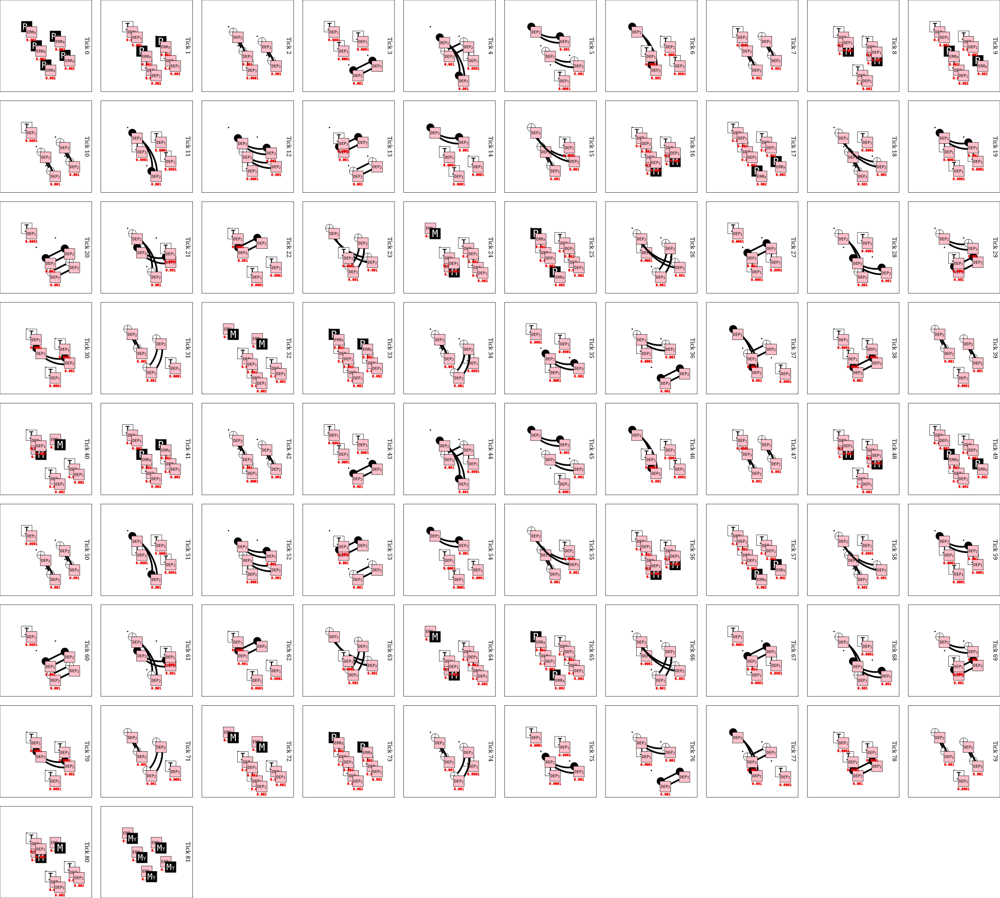

In [19]:
#the gates and noise model
perfect_code_morphing_experiment.diagram('timeslice-svg')

#the detectors
#perfect_code_morphing_experiment.diagram('detslice-svg')

#the observable(s)
#perfect_code_morphing_experiment.diagram('detslice-svg', filter_coords = ["L0", "L1"])

The circuit-distance of stability experiments is not the same as the spatial circuit distance, let's calculate what the distance of this stability experiment is.

In [20]:
from morphing_qec_circuits.misc import circuit_distance

In [21]:
circuit_distance(perfect_code_morphing_experiment)

5

In [22]:
dem = perfect_code_morphing_experiment.detector_error_model()
sampler = dem.compile_sampler()
decoder = MLEDecoder(dem)

n_flips, n_shots = sample_logical_flips(
    sampler,
    decoder,
    batch_size=100,
    target_flips=1000000,
    max_time=10,
)

print("number of logical flips:", n_flips)
print("number of shots:", n_shots)
print("logical error probability:", n_flips/n_shots)


number of logical flips: 0
number of shots: 4100
logical error probability: 0.0


# Reproducing the results of arXiv:2604.09797.


Now that we've demonstrated the basic functionality of the morphing-qec-circuits package, we show how you can reproduce each of the results of arXiv:2604.09797. The raw numerical data can be found in the `used_data` folder and the plots themselves can be reproduced in the `Reproducing_arXiv_2604_09797` notebook, so here we focus on the code behind the raw data so that you can run your own numerical experiments.

## Section 3.3: Case Study: Numerical Search for Morphing Abelian 2BGA Codes

This section concerns morphing circuits for Abelian 2BGA codes. To do this, we have a class that stores information about the Abelian 2BGA code, and contains methods that generate morphing and bare-ancilla circuits for the code. For example, to generate the Gross code of Bravyi et al, one can use the following code.

In [23]:
from morphing_qec_circuits.code_params import Abelian2BGAParams

In [24]:
#The Abelian group should be a product of cyclic groups G = Z_l x Z_m x ...,
# to specify the group we simply list the orders of these groups [l, m, ...].
group = [12,6]

#Elements of the group are represented by lists of length equal to len(group).
# In this example where G = Z_l x Z_m, then the element x^alpha y^beta is represented by [alpha, beta].
a_list = [[3,0],[0,1],[0,2]]
b_list = [[0,3],[1,0],[2,0]]

gross_code = Abelian2BGAParams(group, a_list, b_list, input_format = "group")

Initialising an Abelian2BGAParams object automatically also calculates its "lattice presentation" as described in Appendix C2. This presentation of the code is also given when you print the Abelian2BGAParams object:

In [25]:
print(gross_code)

Abelian2BGAParams(group=[12, 6], a_list=[[3, 0], [0, 1], [0, 2]], b_list=[[0, 3], [1, 0], [2, 0]]; lattice_signature=[2, 2], periodicity_vectors=array([[12,  0,  0,  0],
       [ 2,  2,  0,  0],
       [ 9,  0,  3,  0],
       [ 4,  1,  1,  1]]), n_copies=np.int64(1); [[n,k,d]]=[[144,?,?]])


We can also intialise an Abelian2BGAParams object by specifying its lattice presentation. A group presentation of the code is automatically calculated.

In [26]:
gross_code_2 = Abelian2BGAParams(
    gross_code.lattice_signature,
    gross_code.periodicity_vectors,
    n_copies = 1,
    input_format = "vectors",
)

print(gross_code_2)

Abelian2BGAParams(group=[12, 6], a_list=[[0, 0], [1, 2], [11, 1]], b_list=[[0, 0], [1, 0], [8, 3]]; lattice_signature=[2, 2], periodicity_vectors=array([[12,  0,  0,  0],
       [ 2,  2,  0,  0],
       [ 9,  0,  3,  0],
       [ 4,  1,  1,  1]]), n_copies=1; [[n,k,d]]=[[144,?,?]])


Notice here how the group presentation of gross_code_2 is not the same as that of gross_code. Nevertheless, these represent the same underlying code:

In [27]:
gross_code.is_equivalent(gross_code_2)

True

A purely contracting, homomorphism-based morphing circuit (defined in Appendix C3) for an Abelian 2BGA code can be generated quite easily. The example below reproduces the morphing circuit in Table II of arXiv:2407.16336 under the $xy$ homomorphism.

In [28]:
#Specify the contraction tree for the stabiliser s(X,1).
#The entry format is analogous to the way CNOT_gates is specified in a CSSMorphingSpecifications object,
# except that now the entries are strings "A0", "B0", "A1", "B1", etc. instead of indices,
# and the ordering is such that the stabiliser contracts onto the second element in each list.
# the contraction trees for the remaining stabilisers are fixed by the symmetries of the homomorphism-based circuit.
contraction_tree = [
    [["A0", "B2"], ["B0", "A2"]],
    [["A1", "B2"], ["B1", "A2"]],
    [["B2", "A2"]],
]

#the homomorphism is specified by defining the image of the homomorphism (in the same format as the group attribute),
# and the action of the homomorphism on the generators of the group.
homomorphism_image = [2]
homomorphism_action = [[1],[1]]
#In this example, the homomorphism phi acts from G = Z_12 x Z_6 -> Z_2 = {1,u}, such that phi(x) = phi(y) = u.

b_shift = [1]
#b_shift tells us which coset of Z-stabilisers is contracting at the same time as the kernel(phi) coset of X-stabilisers.

gross_code_morphing_specs = gross_code.get_morphing_specifications(
    contraction_tree,
    homomorphism_image,
    homomorphism_action,
    b_shift,
)


``gross_code_morphing_specs`` is a ``CSSMorphingSpecifications`` object, and therefore you can do all the things with it that we already demonstrated above (like calculating distances, generating memory and stability experiments).

The end-cycle codes of two-round purely-contracting homomorphism-based circuits are themselves Abelian 2BGA codes (Appendix C.3.1), the Abelian2BGAParams object for this can be obtained as follows. This is convenient because, as we demonstrated above, the ``Abelian2BGAParams`` class calculates the lattice presentation and has a method that determines whether two Abelian 2BGA parameters represent the same code, which you wouldn't notice if you simply looked at the ``CSSMorphingSpecifications`` object.

In [29]:

gross_code_end_cycle_code = gross_code.two_round_end_cycle_code(
    contraction_tree,
    homomorphism_action,
    b_shift,
)

gross_code_end_cycle_code.nkd_params()

print(gross_code_end_cycle_code)

Abelian2BGAParams(group=[12, 3], a_list=[[0, 0], [1, 0], [6, 2], [6, 1], [11, 0]], b_list=[[0, 0], [5, 2], [9, 2], [2, 0]]; lattice_signature=[4, 3], periodicity_vectors=array([[12,  0,  0,  0,  0,  0,  0],
       [ 6,  3,  0,  0,  0,  0,  0],
       [ 0,  1,  1,  0,  0,  0,  0],
       [ 1,  0,  0,  1,  0,  0,  0],
       [ 7,  2,  0,  0,  1,  0,  0],
       [ 3,  2,  0,  0,  0,  1,  0],
       [10,  0,  0,  0,  0,  0,  1]]), n_copies=np.int64(1); [[n,k,d]]=[[72,12,6]])


Finally, there is also a function to return a "bare-ancilla" circuit for a given Abelian 2BGA code (although we only used this function in our earlier work arxiv:2407.16336).

In [30]:
#X_order specifies the order in which each X-ancilla interacts with the data qubits around it.
# For example, "A0" indices that each X-ancilla q(X,g) performs a CNOT gate with q(L, A0 * g),
# and "B0" indicates a CNOT gate with q(R, B0 * g).
# An empty string indicates that the X-ancilla does not perform any gate in that gate layer.
#In this example we reproduce the syndrome extraction circuit from Table 5 of arXiv:2308.07915,
# it's fairly straight forward to read off the values of X_order and Z_order straight from the table.
X_order = ["", "A1", "B1", "B0", "B2", "A0", "A2"]
Z_order = ["A0", "A2", "B0", "B1", "B2", "A1", ""]

p = 0.001
T = 5

#We will use this noise model later to reproduce some results from arXiv:2604.09797.
# For now, this is simply the SI1000 noise model.
noise_setup = SI1000_variable_measurement_setup(p,1)
noise_model_generator = lambda qubit_dictionary, noise_setup: ArbitraryGatesSI1000NoiseModel(qubit_dictionary, noise_setup)

IBM_circuit = gross_code.get_bare_ancilla_XZ_memory_circuit(
    X_order,
    Z_order,
    noise_setup,
    T,
    noise_model_generator=noise_model_generator,
)

In [31]:
IBM_circuit.diagram('timeslice-svg')

To reproduce the results in Figures 11, 25, and 26, we have a dedicated function that can perform the search for you.

In [32]:
from morphing_qec_circuits.code_params import Abelian_2BGA_two_round_morphing_search

In [33]:
G_size_list = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24]
lattice_signature_list = [[1,2]]

#this searches over all (mid-cycle) Abelian 2BGA codes with |G| <= 12 (so n <= 24).
# This filters for codes where the number of logical qubits is equal to 8 (set by the "num_logicals" entry in parameter_restrictions)
# It returns all of the mid-cycle codes with the largest distance and fewest number of qubits that satisfy k == 8.
# At the same time, it searches all two-round purely-contracting homomorphism-based morphing circuits for all the mid-cycle
# Abelian 2BGA codes (not just those with the highest mid-cycle distance), and filters again on morphing circuits that
# have connectivity requirements less than or equal to 4 (as specified by the "connectivity" entry in parameter_restrictions).
# It returns the morphing circuits with the largest end-cycle distance and lowest number of qubits subject to k == 8 and c <= 4.
# Because we set keep_equally_performant_circuits to False, it only returns the first code/circuit it finds with optimal parameters.
# There are other parameters that you can minimise, maximise, and restrict on in this function, see the source code for a full description.
my_search_results = Abelian_2BGA_two_round_morphing_search(
    G_size_list,
    lattice_signature_list,
    parameter_restrictions = {"num_logicals": lambda k: k == 8, "connectivity": lambda c: c <= 4},
    parameter_minimisations = ["num_qubits"],
    parameter_maximisations = ["num_logicals", "mid_cycle_distance", "end_cycle_distance"],
    check_mid_cycle_distance = True,
    keep_equally_performant_circuits = False,
)

The above code reproduces the light red squares with $n \leq 24$ and light blue circles with $n \leq 48$ of Figure 11. To recover the morphing circuit (for example to subsequently run memory experiments on the circuit as demonstrated above) you can use the code below.

In [34]:
print(my_search_results)

my_new_morphing_parameters = my_search_results['best_morphing_circuits'][0]
my_new_morphing_specs = my_new_morphing_parameters['mid_cycle_code'].get_morphing_specifications(
    my_new_morphing_parameters['contraction_tree'],
    my_new_morphing_parameters['homomorphism_image'],
    my_new_morphing_parameters['homomorphism_action'],
    my_new_morphing_parameters['b_shift'],
)

{'best_mid_cycle_codes': [Abelian2BGAParams(group=[6, 2, 2], a_list=[[0, 0, 0], [0, 0, 1]], b_list=[[0, 0, 0], [5, 1, 0], [1, 0, 0]]; lattice_signature=[1, 2], periodicity_vectors=array([[2, 0, 0],
       [0, 6, 0],
       [0, 2, 2]]), n_copies=1; [[n,k,d]]=[[48,8,2]])], 'best_mid_cycle_performance_parameters': [{'num_qubits': 48, 'num_logicals': 8, 'mid_cycle_distance': 2}], 'best_morphing_circuits': [{'mid_cycle_code': Abelian2BGAParams(group=[6, 2, 2], a_list=[[0, 0, 0], [0, 0, 1]], b_list=[[0, 0, 0], [5, 1, 0], [1, 0, 0]]; lattice_signature=[1, 2], periodicity_vectors=array([[2, 0, 0],
       [0, 6, 0],
       [0, 2, 2]]), n_copies=1; [[n,k,d]]=[[48,8,2]]), 'contraction_tree': [[['B1', 'A0']], [['B0', 'A0']], [['A1', 'B2']], [['B2', 'A0']]], 'homomorphism_image': [2], 'homomorphism_action': [[0], [0], [1]], 'b_shift': [0]}], 'best_morphing_performance_parameters': [{'num_qubits': 48, 'num_logicals': 8, 'mid_cycle_distance': 2, 'depth': 4, 'connectivity': 4, 'gate_count': 10, 'swap_

## Section 5.2: Case Study: the Hex-grid Colour Code

We benchmarked the performance of a number of circuits pertaining to a colour code on a planar hexagonal-connectivity device, shown in Figure 31. The circuits, and the code we used to obtain the raw data, are shown below. We've labelled the circuits by the colour and shape of the markers in Figure 31 for ease of reference.

In [35]:
from morphing_qec_circuits.code_params import get_triangular_colour_code_superdense_XZ_memory_circuit
from morphing_qec_circuits.morphing import (
    get_triangular_half_shifted_hex_morphing_specifications,
    get_triangular_half_shifted_hex_morphing_specifications_extra_qubits,
    get_unoptimised_shifted_hex_morphing_specifications,
    get_rectangular_centred_hex_morphing_specifications,
)

In [36]:
d = 3
T = d
p = 0.001
noise_setup = SI1000_variable_measurement_setup(p,1)
noise_model_generator = lambda qubit_dictionary, noise_setup: ArbitraryGatesSI1000NoiseModel(qubit_dictionary, noise_setup)
args = (noise_setup, T)
kwargs = {"noise_model_generator": noise_model_generator}

morphing_specs = get_triangular_half_shifted_hex_morphing_specifications(d, extra_layer = False)
light_blue_circles = morphing_specs.get_morphing_XZ_memory_circuit(*args, **kwargs)

morphing_specs = get_triangular_half_shifted_hex_morphing_specifications(d, extra_layer = True)
dark_blue_circles = morphing_specs.get_morphing_XZ_memory_circuit(*args, **kwargs)

morphing_specs = get_triangular_half_shifted_hex_morphing_specifications_extra_qubits(d, extra_layer = True)
red_triangles = morphing_specs.get_morphing_XZ_memory_circuit(*args, **kwargs)

light_green_circles = get_triangular_colour_code_superdense_XZ_memory_circuit(d, *args, **kwargs)

morphing_specs = get_unoptimised_shifted_hex_morphing_specifications(d)
dark_green_circles = morphing_specs.get_morphing_XZ_memory_circuit(*args, **kwargs)

morphing_specs = get_rectangular_centred_hex_morphing_specifications(d)
light_purple_diamonds = morphing_specs.get_morphing_XZ_memory_circuit(*args, **kwargs)

In [37]:
circuit = light_blue_circles

dem = circuit.detector_error_model()
sampler = dem.compile_sampler()
decoder = MLEDecoder(dem)

#the sampling runs batch_size samples at a time. After each batch, it checks if the number of target_flips
# has been reached and if the max_time has been exceeded. If either of these occur then it stops.
# So in this example, setting target_flips to be ridiculously large and max_time to 10 basically means
# it will take a little over 10 seconds to run.
n_flips, n_shots = sample_logical_flips(
    sampler,
    decoder,
    batch_size=100,
    target_flips=1000000,
    max_time=10,
)

print("number of logical flips:", n_flips)
print("number of shots:", n_shots)
print("logical error probability:", n_flips/n_shots)

number of logical flips: 5
number of shots: 1300
logical error probability: 0.0038461538461538464


## Section 6.3: Circuit-level Distance of Stability Experiments

Here we include the code that generates and calculates the circuit distance of the two toric code morphing circuits in Figure 20, that respectively saturate the upper- and lower-bounds of the circuit distance (up to a constant).

In [38]:
from copy import deepcopy
from morphing_qec_circuits.misc import DistanceNoiseModel, uniform_setup

In [39]:
def adversarial_toric_code_specification(d, bad = True):
    if d%4 != 0:
        raise NotImplementedError("adversarial toric code needs to have d divisible by 4")
    rotated_toric_code = Abelian2BGAParams([d, d], [[0,0],[1,0]], [[0,0],[0,-1]])
    contraction_tree = [[["B0", "A0"], ["A1", "B1"]], [["A0", "B1"]]]
    homomorphism_image = [2,2]
    if bad:
        homomorphism_action = [[1,1],[0,1]]
    else:
        homomorphism_action = [[1,1],[1,0]]
    b_shift = [0,0]
    morphing_specs = rotated_toric_code.get_morphing_specifications(
        contraction_tree,
        homomorphism_image,
        homomorphism_action,
        b_shift,
    )
    return morphing_specs

In [40]:
bad_morphing_specs = adversarial_toric_code_specification(4, bad = True)
good_morphing_specs = adversarial_toric_code_specification(4, bad = False)

In [41]:
p = 0.001
T_list = [4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20]
noise_setup = uniform_setup(0.001)

for T in T_list:
    cutoff = np.inf
    #This noise model is useful for calculating the circuit-level distance of CSS circuits (circuits for CSS codes that only use
    # CNOT gates, X/Z measurements and X/Z resets).
    noise_model_generator = lambda qubit_dictionary, noise_setup: DistanceNoiseModel(qubit_dictionary, noise_setup, "X")
    
    stim_circuit_X_errors = bad_morphing_specs.get_morphing_stability_circuit(
        noise_setup,
        T,
        noise_model_generator = noise_model_generator,
    )
    
    X_circuit_distance = circuit_distance(stim_circuit_X_errors, error_basis = "X", cutoff = cutoff)
    
    noise_model_generator = lambda qubit_dictionary, noise_setup: DistanceNoiseModel(qubit_dictionary, noise_setup, "Z")
    
    stim_circuit_Z_errors = bad_morphing_specs.get_morphing_stability_circuit(
        noise_setup,
        T,
        noise_model_generator = noise_model_generator,
    )

    bad_d_stab = circuit_distance(stim_circuit_Z_errors, error_basis = "Z", cutoff = X_circuit_distance)
    cutoff = np.inf
    noise_model_generator = lambda qubit_dictionary, noise_setup: DistanceNoiseModel(qubit_dictionary, noise_setup, "X")
    
    stim_circuit_X_errors = good_morphing_specs.get_morphing_stability_circuit(
        noise_setup,
        T,
        noise_model_generator = noise_model_generator,
    )
    
    X_circuit_distance = circuit_distance(stim_circuit_X_errors, error_basis = "X", cutoff = cutoff)
    
    noise_model_generator = lambda qubit_dictionary, noise_setup: DistanceNoiseModel(qubit_dictionary, noise_setup, "Z")
    
    stim_circuit_Z_errors = good_morphing_specs.get_morphing_stability_circuit(
        noise_setup,
        T,
        noise_model_generator = noise_model_generator,
    )

    good_d_stab = circuit_distance(stim_circuit_Z_errors, error_basis = "Z", cutoff = X_circuit_distance)
    
    print(f"T = {T}, bad d_stab = {bad_d_stab}, good d_stab = {good_d_stab}")

T = 4, bad d_stab = 1, good d_stab = 1
T = 5, bad d_stab = 1, good d_stab = 1
T = 6, bad d_stab = 2, good d_stab = 2
T = 7, bad d_stab = 2, good d_stab = 2
T = 8, bad d_stab = 2, good d_stab = 3
T = 9, bad d_stab = 3, good d_stab = 3
T = 10, bad d_stab = 3, good d_stab = 4
T = 11, bad d_stab = 3, good d_stab = 4
T = 12, bad d_stab = 4, good d_stab = 5
T = 13, bad d_stab = 4, good d_stab = 5
T = 14, bad d_stab = 4, good d_stab = 6
T = 15, bad d_stab = 5, good d_stab = 6
T = 16, bad d_stab = 5, good d_stab = 7
T = 17, bad d_stab = 5, good d_stab = 7
T = 18, bad d_stab = 6, good d_stab = 8
T = 19, bad d_stab = 6, good d_stab = 8
T = 20, bad d_stab = 6, good d_stab = 9


You can clearly see bad d_stab equals $\lfloor T/3\rfloor$ while good d_stab equals $\lfloor T/2\rfloor - 1$, and therefore satisfy the lower- and upper-bounds for the circuit-level stability distance (Eq 19) of a $J=4$ morphing circuit up to a constant.

## Section 6.4: Single-Shot Error Correction and the 3D Toric Code

The morphing circuit for the 3D toric code described in Figure 21 is also included in the `morphing-qec-circuits` package.

In [42]:
from morphing_qec_circuits.morphing import get_3D_toric_code_morphing_specifications

In [43]:
d = 4
three_D_toric_code_morphing_specs = get_3D_toric_code_morphing_specifications(d)

In all of the previous examples, the stability experiments generated for the morphing specifications assume that all redundancies in the code correspond to *observables* in the stability experiment; that is, they are used to test the performance of the stability experiment and not as detectors to be used in decoding. This, of course, is *not* what we want in the 3D toric code: the product of $Z$-checks around each cube in the 3D toric code should be used by the decoder to infer the measurement errors on the $Z$-checks. To this end we can use the meta_checks attribute of the (CSS)MorphingSpecifications object to list all of the redundancies that should be passed to the decoder. Then, when the stability experiment is generated, the meta-checks will appear as detectors, and only the redundancies that are not generated by the meta-checks will appear as observables. This is already taken care of in the `get_3D_toric_code_morphing_specifications` function:

In [44]:
print("Number of meta-checks among X stabilisers:", len(three_D_toric_code_morphing_specs.meta_checks["X"]))
print("Number of meta-checks among Z stabilisers:", len(three_D_toric_code_morphing_specs.meta_checks["Z"]))

Number of meta-checks among X stabilisers: 0
Number of meta-checks among Z stabilisers: 32


So now, when we generate a $Z$-basis stability experiment, we see that the circuit-level stability distance is greater than the number of measurement rounds, which is a consequence of the fact that the 3D toric code is single-shot against measurement errors on $Z$-checks. Note that measurement errors on $Z$-checks are basically $X$-errors occurring immediately before the measurement, so the experiment below is searching for the lowest-weight circuit-level $X$-error that flips one of the non-local redundancies between $Z$-checks.

In [45]:
p = 0.001
T = 6
noise_setup = uniform_setup(0.001)

#Setting cutoff to T + 1 means that the distance-finding algorithm will stop if it is able to show that the distance is
# greater than or equal to T + 1, and it will simply return T + 1. This is mainly to save time because the actual
# circuit-distance here is quite large.
cutoff = T + 1
#This noise model is useful for calculating the circuit-level distance of CSS circuits (circuits for CSS codes that only use
# CNOT gates, X/Z measurements and X/Z resets).
noise_model_generator = lambda qubit_dictionary, noise_setup: DistanceNoiseModel(qubit_dictionary, noise_setup, "X")

stim_circuit_X_errors = three_D_toric_code_morphing_specs.get_morphing_stability_circuit(
    noise_setup,
    T,
    noise_model_generator = noise_model_generator,
)

X_circuit_distance = circuit_distance(stim_circuit_X_errors, error_basis = "X", cutoff = cutoff)

print('Circuit-level stability distance against X-errors is greater than T?', X_circuit_distance > T)

Circuit-level stability distance against X-errors is greater than T? True


## Section 7: Morphing Circuits under Biased Measurement versus Reset Noise

We benchmarked the performance of a number of circuits pertaining to stability experiments on a toric and colour codes under a biased measurement-reset noise model, shown in Figure 23. The circuits, and the code we used to obtain the raw data, are shown below. We've labelled the circuits by subplot in Figure 23 and the circuit number for ease of reference.

In [46]:
from morphing_qec_circuits.code_params import toric_colour_code, ToricCodeParams

In [47]:
d = 4
T = 5
p = 0.001
#setting eta = 1 reproduces the SI1000 noise model, setting eta = 0.4 equalises the measurement and reset noise rates.
eta = 2
noise_setup = SI1000_variable_measurement_setup(p, eta)
noise_model_generator = lambda qubit_dictionary, noise_setup: ArbitraryGatesSI1000NoiseModel(qubit_dictionary, noise_setup)
args = (noise_setup, T)
kwargs = {"noise_model_generator": noise_model_generator}

my_code = toric_colour_code(d, geometry = "twisted-for-half-shifted-hex")

morphing_specs = my_code.get_colour_code_morphing_specifications("x", "hex", "half-shifted", simple_detectors = True)
subplot_a_circuit_I = morphing_specs.get_morphing_XZ_stability_circuit(*args, **kwargs)
subplot_b_circuit_I = morphing_specs.get_morphing_XZ_stability_circuit_XYZ_permutation(*args, **kwargs)

morphing_specs = my_code.get_colour_code_morphing_specifications("x", "hex", "half-shifted", simple_detectors = False)
subplot_a_circuit_II = morphing_specs.get_morphing_XZ_stability_circuit(*args, **kwargs)
subplot_b_circuit_II = morphing_specs.get_morphing_XZ_stability_circuit_XYZ_permutation(*args, **kwargs)

my_code = ToricCodeParams(d)

morphing_specs = my_code.get_toric_standard_morphing_specifications()
subplot_c_circuit_I = morphing_specs.get_morphing_XZ_stability_circuit(*args, **kwargs)

morphing_specs = my_code.get_toric_scrambled_morphing_specifications()
subplot_c_circuit_II = morphing_specs.get_morphing_XZ_stability_circuit(*args, **kwargs)

morphing_specs = my_code.get_toric_hex_scrambled_morphing_specifications()
subplot_c_circuit_III = morphing_specs.get_morphing_XZ_stability_circuit(*args, **kwargs)

The colour code circuits (subplots a and b) use an MLE decoder.

In [48]:
circuit = subplot_a_circuit_I

dem = circuit.detector_error_model()
sampler = dem.compile_sampler()
decoder = MLEDecoder(dem)

#the sampling runs batch_size samples at a time. After each batch, it checks if the number of target_flips
# has been reached and if the max_time has been exceeded. If either of these occur then it stops.
# So in this example, setting target_flips to be ridiculously large and max_time to 10 basically means
# it will take a little over 10 seconds to run.
n_flips, n_shots = sample_logical_flips(
    sampler,
    decoder,
    batch_size=100,
    target_flips=1000000,
    max_time=10,
)

print("number of logical flips:", n_flips)
print("number of shots:", n_shots)
print("logical error probability:", n_flips/n_shots)

number of logical flips: 1
number of shots: 300
logical error probability: 0.0033333333333333335


The toric code circuits (subplot c) use `BeliefMatching`. This isn't a prerequisite of `morphing-qec-circuits` so only run this if you have also installed `BeliefMatching`.

In [49]:
from beliefmatching import BeliefMatching

In [50]:
circuit = subplot_c_circuit_I
max_bp_iters = 40

dem = circuit.detector_error_model(decompose_errors=True)
sampler = dem.compile_sampler()
decoder = BeliefMatching(dem, max_bp_iters = max_bp_iters)

#the sampling runs batch_size samples at a time. After each batch, it checks if the number of target_flips
# has been reached and if the max_time has been exceeded. If either of these occur then it stops.
# So in this example, setting target_flips to be ridiculously large and max_time to 10 basically means
# it will take a little over 10 seconds to run.
n_flips, n_shots = sample_logical_flips(
    sampler,
    decoder,
    batch_size=100,
    target_flips=1000000,
    max_time=10,
)

print("number of logical flips:", n_flips)
print("number of shots:", n_shots)
print("logical error probability:", n_flips/n_shots)

number of logical flips: 42
number of shots: 11900
logical error probability: 0.0035294117647058825
